# 04 — Figures

**Reads:** `data/processed/matched.csv`, `results/tables/*.csv`. **Writes:** `results/figures/fig1_*.png`, `fig2_*.png`.

- Fig 1: log child income against log parent income, single-year vs multi-year parent income (two panels or two fits).
- Fig 2: the IGE estimate by the child's age at measurement, with confidence bands.

Rules carried over from Posts 4–5: title states the finding, axis labels with units, legend, source line,
no explanatory prose inside the figure, check on the published page. Use `plot_style.py`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plot_style import apply_style, COLORS, SITE, source_note

apply_style()

ROOT = Path.cwd().parent
PROC, TAB, FIG = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def dollar_ticks(axis, values):
    """Ticks in dollars on an axis that is in log dollars."""
    axis.set_ticks(np.log(values))
    axis.set_ticklabels([f"${v / 1000:,.0f}k" for v in values])

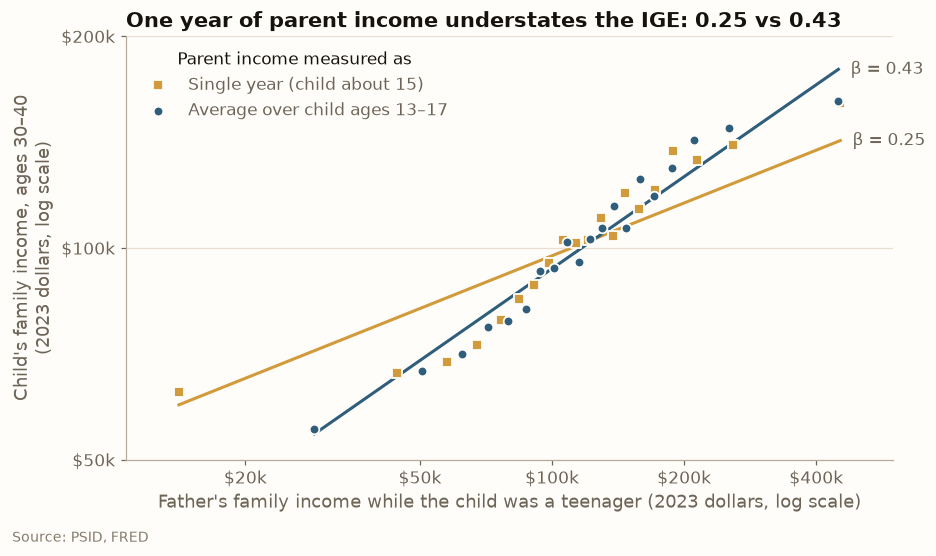

In [3]:
# Fig 1: binned scatter of log child income on log parent income, single-year vs multi-year parent income
matched = pd.read_csv(PROC / "matched.csv")
est = pd.read_csv(TAB / "ige_estimates.csv").query("sample == 'SRC'").set_index("parent_income")

# Same children as the SRC rows of ige_estimates.csv (notebook 03, section 5)
d = matched[(matched["id_1968"] <= 2930) & (matched["parent_years"] >= 2)
            & (matched["parent_inc_single"] > 0) & (matched["parent_inc_avg"] > 0)
            & (matched["child_inc_30_40"] > 0)]
assert len(d) == est["n"].iloc[0]

N_BINS = 20
series = [  # column, legend label, row in ige_estimates.csv, color, marker
    ("parent_inc_single", "Single year (child about 15)", "single year (child age ~15)", COLORS["part2"], "s"),
    ("parent_inc_avg", "Average over child ages 13–17", "average, child ages 13-17", COLORS["part1"], "o"),
]
ly = np.log(d["child_inc_30_40"])

fig, ax = plt.subplots()
for col, label, row, color, marker in series:
    lx = np.log(d[col])
    slope, intercept = np.polyfit(lx, ly, 1)
    assert np.isclose(slope, est.loc[row, "beta"])          # the line is the regression in the table
    bins = pd.DataFrame({"x": lx, "y": ly}).groupby(pd.qcut(lx, N_BINS, labels=False)).mean()
    ax.scatter(bins["x"], bins["y"], s=40, color=color, marker=marker,
               edgecolor=SITE["paper"], linewidth=1.2, zorder=3, label=label)
    xs = np.array([bins["x"].min(), bins["x"].max()])
    ax.plot(xs, intercept + slope * xs, color=color, linewidth=2, zorder=2)
    ax.annotate(f"β = {slope:.2f}", (xs[1], intercept + slope * xs[1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=11, color=SITE["muted"])

dollar_ticks(ax.xaxis, [10_000, 20_000, 50_000, 100_000, 200_000, 400_000])
dollar_ticks(ax.yaxis, [50_000, 100_000, 200_000])
ax.set_xlabel("Father's family income while the child was a teenager (2023 dollars, log scale)")
ax.set_ylabel("Child's family income, ages 30–40\n(2023 dollars, log scale)")
ax.set_title(f"One year of parent income understates the IGE: {est['beta'].iloc[0]:.2f} vs {est['beta'].iloc[1]:.2f}")
ax.legend(title="Parent income measured as", title_fontsize=11, loc="upper left")
ax.margins(x=0.08)
source_note(fig, "PSID, FRED")
fig.savefig(FIG / "fig1_ige_single_vs_multi.png")
plt.show()

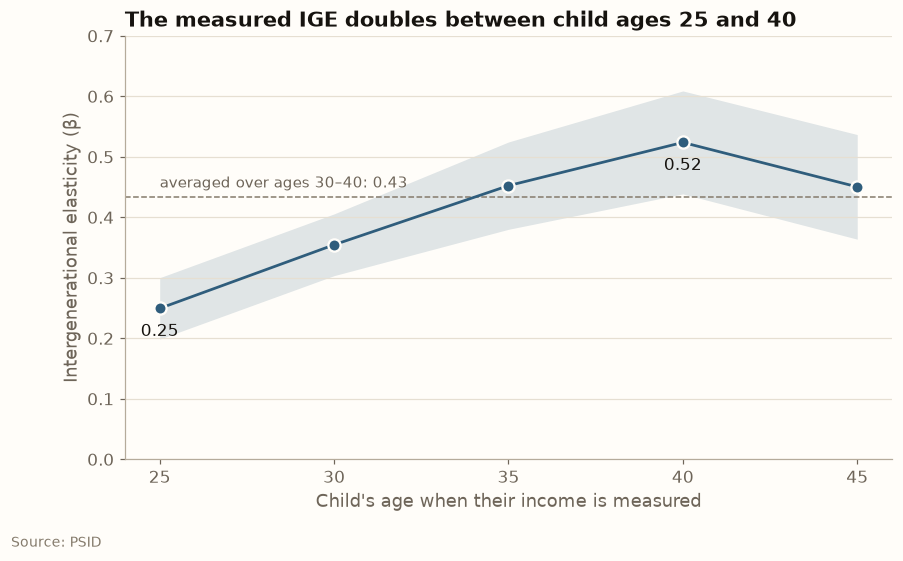

In [5]:
# Fig 2: IGE by the child's age at measurement, 95% confidence band
by_age = pd.read_csv(TAB / "ige_by_child_age.csv")
main = est.loc["average, child ages 13-17", "beta"]   # child income averaged over ages 30-40
lo, hi = by_age["beta"] - 1.96 * by_age["se"], by_age["beta"] + 1.96 * by_age["se"]

fig, ax = plt.subplots()
ax.fill_between(by_age["child_age"], lo, hi, color=COLORS["part1"], alpha=0.15, linewidth=0)
ax.plot(by_age["child_age"], by_age["beta"], color=COLORS["part1"], marker="o", markersize=8,
        markeredgecolor=SITE["paper"], markeredgewidth=1.5, zorder=3)
ax.axhline(main, color=SITE["faint"], linestyle="--", linewidth=1)
ax.annotate(f"averaged over ages 30–40: {main:.2f}", (by_age["child_age"].min(), main),
            xytext=(0, 6), textcoords="offset points", fontsize=10, color=SITE["muted"])
for _, r in by_age[by_age["child_age"].isin([25, 40])].iterrows():
    ax.annotate(f"{r['beta']:.2f}", (r["child_age"], r["beta"]), xytext=(0, -18), textcoords="offset points",
                ha="center", fontsize=11, color=SITE["ink"])

ax.set_xticks(by_age["child_age"])
ax.set_ylim(0, 0.7)
ax.set_xlabel("Child's age when their income is measured")
ax.set_ylabel("Intergenerational elasticity (β)")
ax.set_title("The measured IGE doubles between child ages 25 and 40")
source_note(fig, "PSID",
            y=-0.03)
fig.savefig(FIG / "fig2_ige_by_child_age.png")
plt.show()